<a href="https://colab.research.google.com/github/sami01979/ai_text_detection/blob/main/ai_text_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv"); test = pd.read_csv("test.csv")

vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform(train.text)
Xte = vec.transform(test.text)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xtr, train.label)
pred = clf.predict(Xte)

p, r, f1, _ = precision_recall_fscore_support(test.label, pred, average="binary")
print("BASELINE  acc=%.4f  P=%.4f  R=%.4f  F1=%.4f" % (accuracy_score(test.label, pred), p, r, f1))
print(confusion_matrix(test.label, pred))

BASELINE  acc=0.8389  P=0.8328  R=0.8478  F1=0.8403
[[830 170]
 [152 847]]


In [2]:
!pip install -q transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00


In [4]:
import numpy as np, pandas as pd, torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

MODEL = "roberta-base"      # use "distilroberta-base" if training is too slow
MAX_LEN = 256

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv"); test = pd.read_csv("test.csv")
tok = AutoTokenizer.from_pretrained(MODEL)

def prep(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
    return ds.remove_columns(["text"])

tr, va, te = prep(train), prep(val), prep(test)

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)

def metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

args = TrainingArguments(
    output_dir="out",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=va,
                  processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metrics)
trainer.train()

# Final test evaluation
out = trainer.predict(te)
preds = np.argmax(out.predictions, axis=-1)
print(out.metrics)
print(confusion_matrix(out.label_ids, preds))

trainer.save_model("final_model")

Map:   0%|          | 0/15987 [00:00<?, ? examples/s]

Map:   0%|          | 0/1998 [00:00<?, ? examples/s]

Map:   0%|          | 0/1999 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.191204,0.309795,0.896897,0.853072,0.958959,0.902922
2,0.144157,0.603194,0.881381,0.816445,0.983984,0.892419


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'test_loss': 0.24739967286586761, 'test_accuracy': 0.9069534767383692, 'test_precision': 0.8732782369146006, 'test_recall': 0.9519519519519519, 'test_f1': 0.9109195402298851, 'test_runtime': 7.1821, 'test_samples_per_second': 278.331, 'test_steps_per_second': 4.456}
[[862 138]
 [ 48 951]]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ROC-AUC: 0.9797452452452454
              precision    recall  f1-score   support

       Human     0.9473    0.8620    0.9026      1000
          AI     0.8733    0.9520    0.9109       999

    accuracy                         0.9070      1999
   macro avg     0.9103    0.9070    0.9068      1999
weighted avg     0.9103    0.9070    0.9068      1999



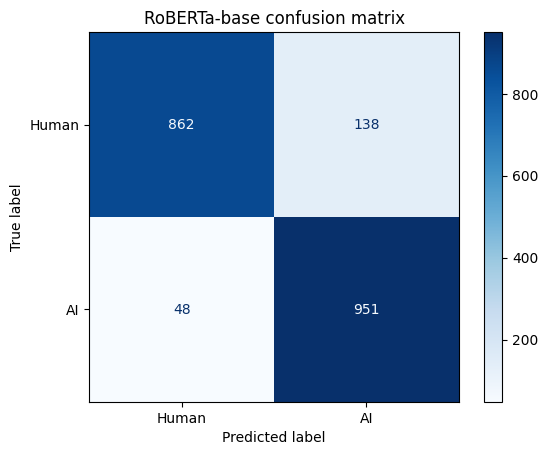

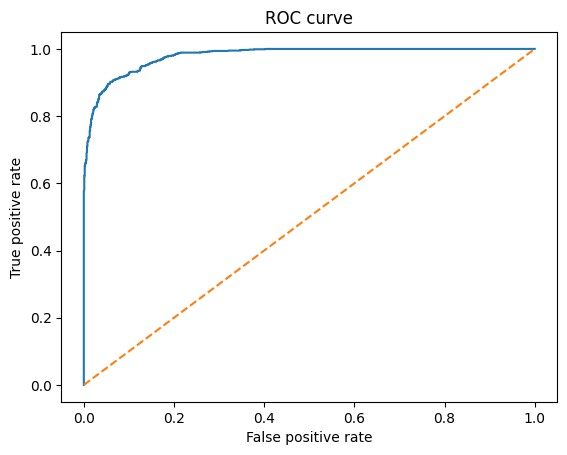

                                                   text  label  pred
89    7 January 2017 Last updated at 17:08 GMT It is...      0     1
1934  Energy will travel via the world's longest sub...      1     0
680   Cathy wanted to try infusing her water. Cathy ...      1     0
371   Did not eat here. I arrived for a late lunch t...      0     1
1745  If you could invite anyone to speak at the Ath...      0     1


In [5]:
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay, classification_report
from scipy.special import softmax
import matplotlib.pyplot as plt

probs = softmax(out.predictions, axis=-1)[:, 1]
print("ROC-AUC:", roc_auc_score(out.label_ids, probs))
print(classification_report(out.label_ids, preds, target_names=["Human", "AI"], digits=4))

ConfusionMatrixDisplay.from_predictions(out.label_ids, preds, display_labels=["Human", "AI"], cmap="Blues")
plt.title("RoBERTa-base confusion matrix")
plt.savefig("cm_roberta.png", dpi=200, bbox_inches="tight"); plt.show()

fpr, tpr, _ = roc_curve(out.label_ids, probs)
plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve")
plt.savefig("roc_roberta.png", dpi=200, bbox_inches="tight"); plt.show()

# Wrong predictions, for error analysis
test_df = test.reset_index(drop=True).copy()
test_df["pred"] = preds
errors = test_df[test_df.label != test_df.pred]
errors.sample(10, random_state=1).to_csv("errors_sample.csv", index=False)
print(errors.sample(5, random_state=1)[["text", "label", "pred"]])

In [6]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r final_model cm_roberta.png roc_roberta.png errors_sample.csv /content/drive/MyDrive/

Mounted at /content/drive


In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

path = "final_model"   # or "/content/drive/MyDrive/final_model"
tok = AutoTokenizer.from_pretrained(path)
model = AutoModelForSequenceClassification.from_pretrained(path)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device).eval()

def detect(text):
    inputs = tok(text, truncation=True, max_length=256, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=-1)[0]
    ai_prob = probs[1].item()
    label = "AI-generated" if ai_prob >= 0.5 else "Human-written"
    print(f"{label}  (AI probability: {ai_prob:.1%})")

detect("hey , what do you think is it ai written or human written , if i want to trick you with ai and human mixed will you able to figure it out?")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Human-written  (AI probability: 0.1%)


In [9]:
detect("Last week, I decided to learn Python because I wanted to build something useful for my university project. At first, everything seemed confusing, especially when I encountered errors that I couldn't understand")

AI-generated  (AI probability: 99.4%)


In [10]:
detect("Artificial intelligence is transforming the modern world by improving efficiency, automating repetitive tasks, and enabling innovative solutions across various industries. In education, AI-pow-ered tools can provide personalized learning experiences, assist teachers in evaluating student performance, and make educational resources more accessible. Similarly, businesses use AI to analyze large volumes of data, identify patterns, and support informed decision-making. Despite these advantages, the increasing adoption of artificial intelligence also raises concerns about privacy, employment, and ethical responsibility. Therefore, it is essential to develop and implement AI technologies carefully to ensure that their benefits are maximized while potential risks are minimized.")

AI-generated  (AI probability: 99.8%)


In [12]:
detect('''"Easy on Me" is a song by English singer Adele from her fourth studio album, 30 (2021). Adele wrote the song with its producer, Greg Kurstin. Columbia Records released it as the album's lead single on 15 October 2021. A torch ballad, "Easy on Me" places emphas   is on Adele's vocals over piano instrumentation. In the song, she addresses her divorce and pleads for forgiveness and understanding. It received positive reviews from music critics, who praised her vocals and the lyrics. "Easy on Me" won the Grammy Award for Best Pop Solo Performance and the Brit Award for Song of the Year. The song reached number one on the charts in several countries. Xavier Dolan directed the music video, which references previous Adele videos and depicts her moving out of the house featured in the "Hello" music video. She performed it at the NRJ Music Awards, on her television specials, and at the concert residency Weekends with Adele. Many artists sang cover versions of it. (This article is part of a featured topic: 30 (album).)''')

AI-generated  (AI probability: 86.7%)


AI-generated  (AI probability: 90.1%)
